# Analyse exploratoire (EDA) — Dataset `Prostate_Cancer.csv`

**Objectif du projet :** peut-on prédire si une tumeur de la prostate est **bénigne (B) ou maligne (M)**, afin d'éviter des biopsies inutiles ?

Contrairement au premier dataset (Stamey), celui-ci contient bien la cible **`diagnosis_result`** (B/M).

**Plan**
1. Chargement et description des variables
2. Qualité des données
3. Analyse de la cible
4. Analyse univariée
5. Comparaison bénin vs malin
6. Corrélations et redondances
7. 🚩 Anomalie : `radius` et `texture` incohérents
8. 🚩 Anomalie : fichier trié selon la cible
9. Valeurs aberrantes
10. Vue multivariée (ACP) et modèle de référence
11. Synthèse des tendances

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)
PAL = {"B": "#2a9d8f", "M": "#e76f51"}

## 1. Chargement et description des variables

In [2]:
df = pd.read_csv("../data/Prostate_Cancer.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (100, 10)


,id,diagnosis_result,radius,texture,perimeter,area,smoothness,compactness,symmetry,fractal_dimension
0,1,M,23,12,151,954,0.143,0.278,0.242,0.079
1,2,B,9,13,133,1326,0.143,0.079,0.181,0.057
2,3,M,21,27,130,1203,0.125,0.160,0.207,0.060
3,4,M,14,16,78,386,0.070,0.284,0.260,0.097
4,5,M,9,19,135,1297,0.141,0.133,0.181,0.059


| Variable | Signification (mesure du noyau cellulaire sur image) | Type |
|---|---|---|
| `id` | identifiant du patient | — |
| `diagnosis_result` | **cible** : B = bénin, M = malin | binaire |
| `radius` | rayon du noyau | entier |
| `texture` | variation des niveaux de gris | entier |
| `perimeter` | périmètre | entier |
| `area` | aire | entier |
| `smoothness` | régularité locale du contour | continue |
| `compactness` | périmètre² / aire − 1 | continue |
| `symmetry` | symétrie | continue |
| `fractal_dimension` | complexité du contour | continue |

> ℹ️ Ces variables sont exactement celles du célèbre dataset *Breast Cancer Wisconsin* (mesures de noyaux cellulaires sur images de cytoponctions). Ce dataset Kaggle en est très probablement une version dérivée. À mentionner dans le rapport : la provenance « prostate » n'est pas documentée.

## 2. Qualité des données

In [3]:
df.info()
print("\nValeurs manquantes :", df.isna().sum().sum())
print("Doublons (hors id) :", df.drop(columns="id").duplicated().sum())
print("id unique et continu 1..100 :", df["id"].is_unique and (df["id"] == range(1, 101)).all())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 100 non-null    int64  
 1   diagnosis_result   100 non-null    object 
 2   radius             100 non-null    int64  
 3   texture            100 non-null    int64  
 4   perimeter          100 non-null    int64  
 5   area               100 non-null    int64  
 6   smoothness         100 non-null    float64
 7   compactness        100 non-null    float64
 8   symmetry           100 non-null    float64
 9   fractal_dimension  100 non-null    float64
dtypes: float64(4), int64(5), object(1)
memory usage: 7.9+ KB

Valeurs manquantes : 0
Doublons (hors id) : 0
id unique et continu 1..100 : True


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,100.0,50.500,29.011,1.000,25.750,50.500,75.250,100.000
radius,100.0,16.850,4.879,9.000,12.000,17.000,21.000,25.000
texture,100.0,18.230,5.193,11.000,14.000,17.500,22.250,27.000
perimeter,100.0,96.780,23.676,52.000,82.500,94.000,114.250,172.000
area,100.0,702.880,319.711,202.000,476.750,644.000,917.000,1878.000
smoothness,100.0,0.103,0.015,0.070,0.093,0.102,0.112,0.143
compactness,100.0,0.127,0.061,0.038,0.081,0.118,0.157,0.345
symmetry,100.0,0.193,0.031,0.135,0.172,0.190,0.209,0.304
fractal_dimension,100.0,0.065,0.008,0.053,0.059,0.063,0.069,0.097


## 3. Analyse de la cible

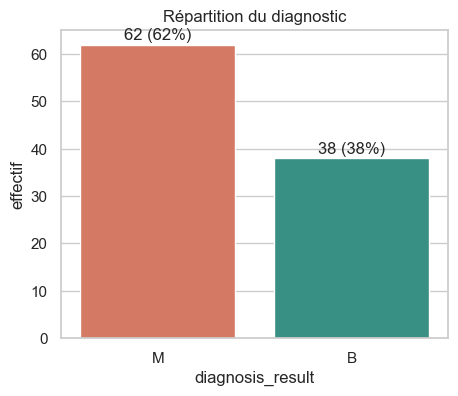

In [5]:
vc = df["diagnosis_result"].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=vc.index, y=vc.values, hue=vc.index, palette=PAL, legend=False, ax=ax)
for i, v in enumerate(vc.values):
    ax.text(i, v + 1, f"{v} ({v/len(df):.0%})", ha="center")
ax.set_title("Répartition du diagnostic"); ax.set_ylabel("effectif")
plt.show()

➡️ **62 % malins / 38 % bénins** : déséquilibre modéré. On utilisera une validation croisée **stratifiée** et des métriques comme l'AUC, le rappel (sensibilité) et le F1, pas seulement l'accuracy. Un modèle qui prédit toujours « M » obtient déjà 62 % d'accuracy.

## 4. Analyse univariée

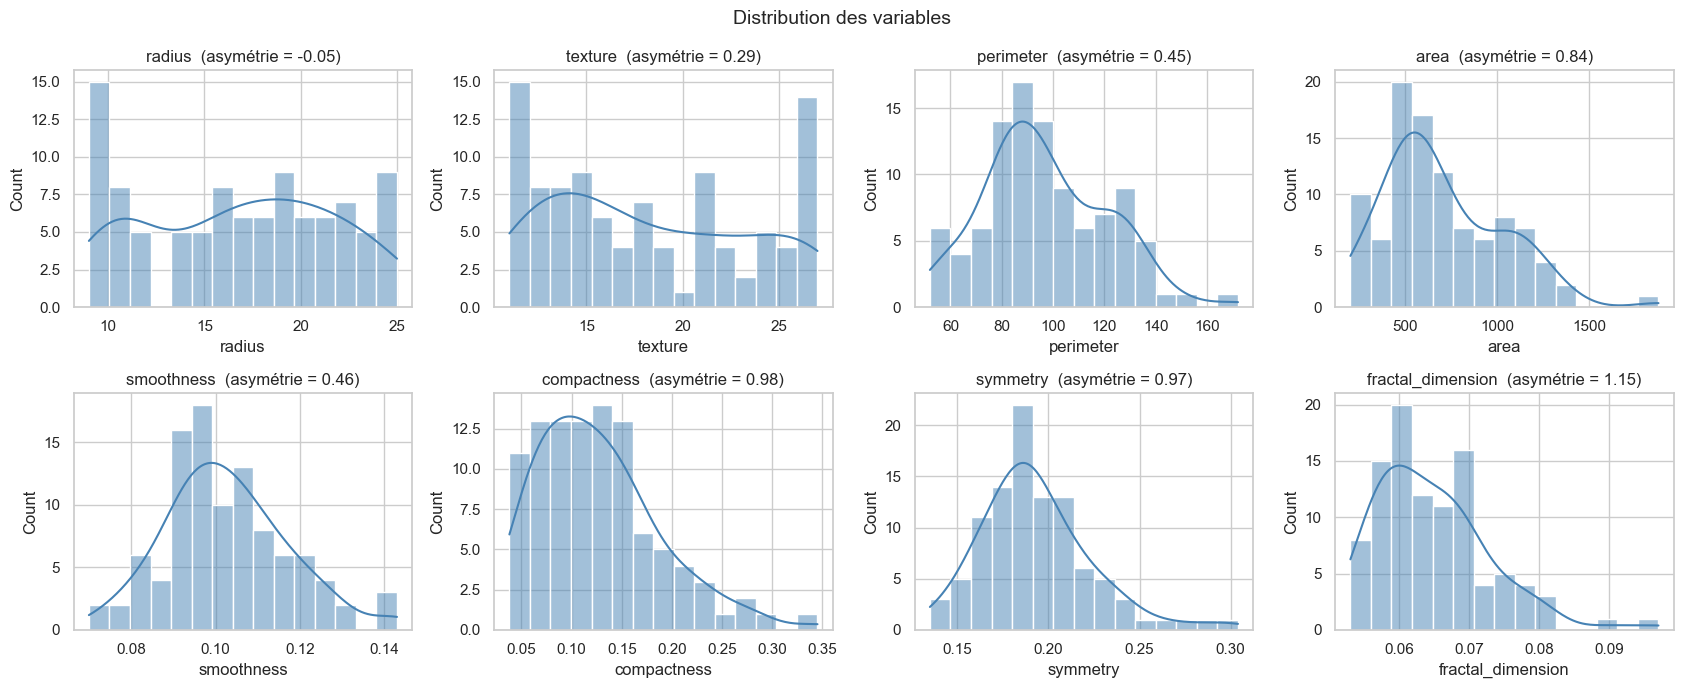

In [6]:
features = ["radius", "texture", "perimeter", "area",
            "smoothness", "compactness", "symmetry", "fractal_dimension"]

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue", bins=15)
    ax.set_title(f"{col}  (asymétrie = {df[col].skew():.2f})")
plt.suptitle("Distribution des variables", fontsize=14)
plt.tight_layout(); plt.show()

In [7]:
res = []
for col in features:
    w, p = stats.shapiro(df[col])
    res.append({"variable": col, "asymétrie": df[col].skew(), "p Shapiro": p, "normale (5%)": p > 0.05})
pd.DataFrame(res).set_index("variable")

,asymétrie,p Shapiro,normale (5%)
variable,,,
radius,-0.055,2.352e-04,False
texture,0.294,1.699e-05,False
perimeter,0.446,4.524e-02,False
area,0.836,2.214e-04,False
smoothness,0.463,1.663e-01,True
compactness,0.975,1.452e-04,False
symmetry,0.975,6.790e-04,False
fractal_dimension,1.153,2.618e-05,False


- `area`, `compactness`, `symmetry` et `fractal_dimension` sont **asymétriques à droite**. Une transformation log pourra aider les modèles linéaires.
- `radius` et `texture` ont une distribution **très plate (quasi uniforme)**, ce qui est inhabituel pour une mesure biologique (voir section 7).

## 5. Comparaison bénin vs malin

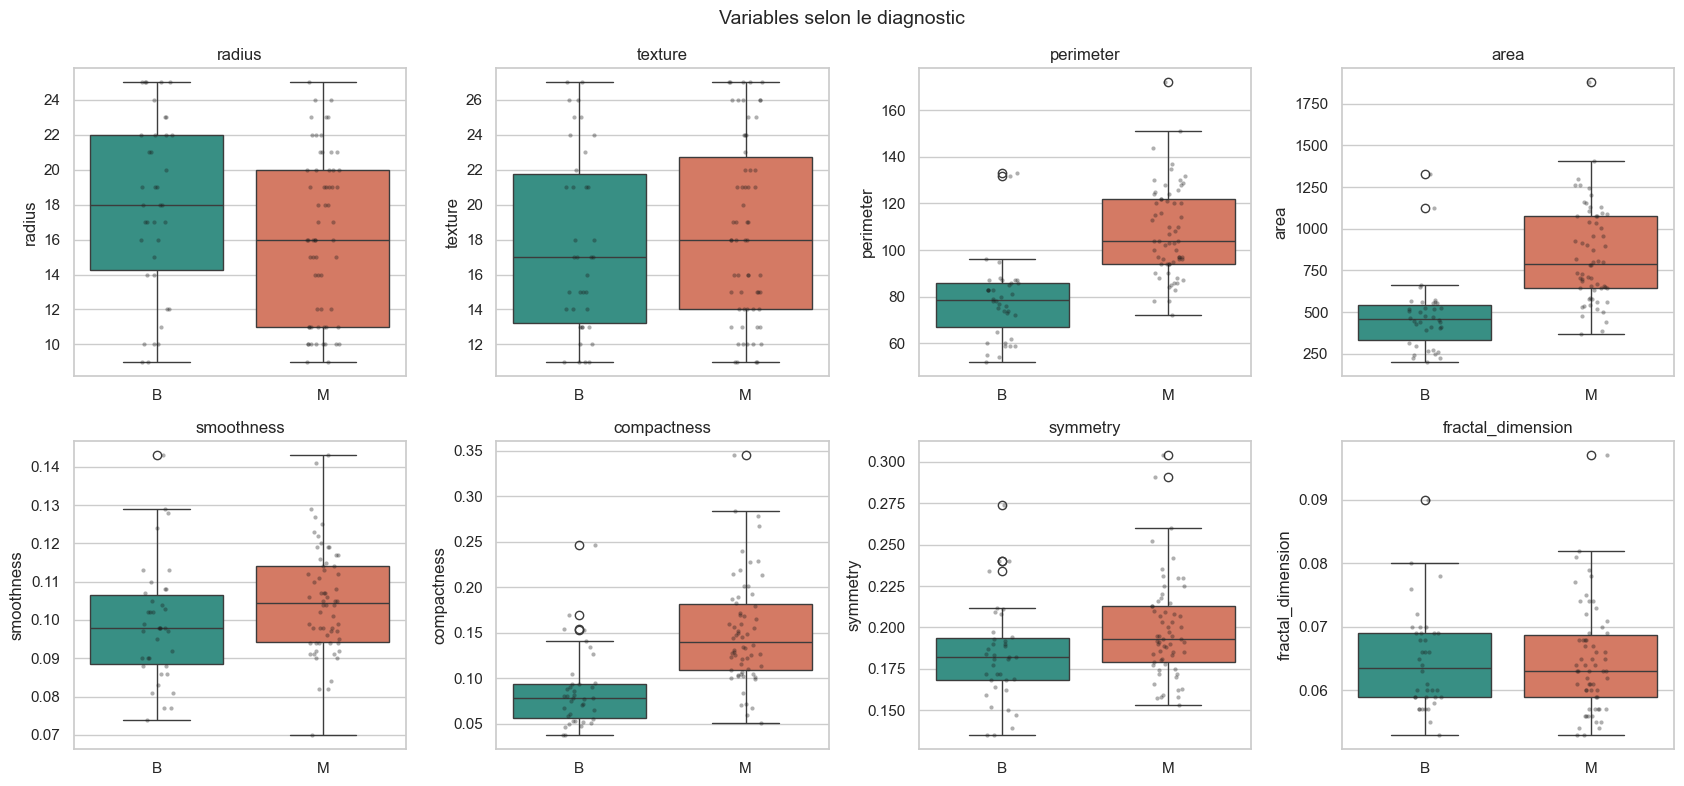

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x="diagnosis_result", y=col, hue="diagnosis_result",
                palette=PAL, order=["B", "M"], legend=False, ax=ax)
    sns.stripplot(data=df, x="diagnosis_result", y=col, order=["B", "M"],
                  color="k", alpha=.35, size=3, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Variables selon le diagnostic", fontsize=14)
plt.tight_layout(); plt.show()

In [9]:
y = (df["diagnosis_result"] == "M").astype(int)
rows = []
for col in features:
    m, b = df.loc[y == 1, col], df.loc[y == 0, col]
    rows.append({
        "variable": col,
        "moyenne B": b.mean(), "moyenne M": m.mean(),
        "écart M vs B (%)": 100 * (m.mean() - b.mean()) / b.mean(),
        "p Mann-Whitney": stats.mannwhitneyu(m, b).pvalue,
        "AUC": roc_auc_score(y, df[col]),
    })
comp = pd.DataFrame(rows).set_index("variable").sort_values("AUC", ascending=False)
comp.style.format({"p Mann-Whitney": "{:.1e}", "écart M vs B (%)": "{:+.0f}%",
                   "AUC": "{:.2f}", "moyenne B": "{:.3f}", "moyenne M": "{:.3f}"}) \
    .background_gradient(subset="AUC", cmap="Greens", vmin=0.5, vmax=0.9)

,moyenne B,moyenne M,écart M vs B (%),p Mann-Whitney,AUC
variable,,,,,
perimeter,78.500,107.984,+38%,3.9e-11,0.89
area,474.342,842.952,+78%,1.4e-10,0.88
compactness,0.087,0.151,+74%,1.0e-08,0.84
symmetry,0.184,0.199,+8%,1.3e-02,0.65
smoothness,0.099,0.105,+6%,3.0e-02,0.63
texture,17.763,18.516,+4%,4.5e-01,0.54
fractal_dimension,0.065,0.065,+0%,9.7e-01,0.50
radius,17.947,16.177,-10%,9.1e-02,0.40


**Tendances :**
- Les tumeurs malignes ont des noyaux **plus grands** : `perimeter` +37 %, `area` +78 % (AUC ≈ 0,88–0,89). Ce sont les meilleurs prédicteurs.
- Elles sont aussi **plus compactes / irrégulières** : `compactness` +74 % (AUC ≈ 0,84).
- `symmetry` et `smoothness` sont légèrement plus élevées chez les malins (AUC ≈ 0,63–0,65, significatif à 5 %).
- `texture` et `fractal_dimension` **ne discriminent pas** (AUC ≈ 0,5).
- `radius` a une AUC < 0,5 : les malins auraient un rayon *plus petit*, ce qui contredit `perimeter` et `area`. C'est incohérent (section 7).

## 6. Corrélations et redondances

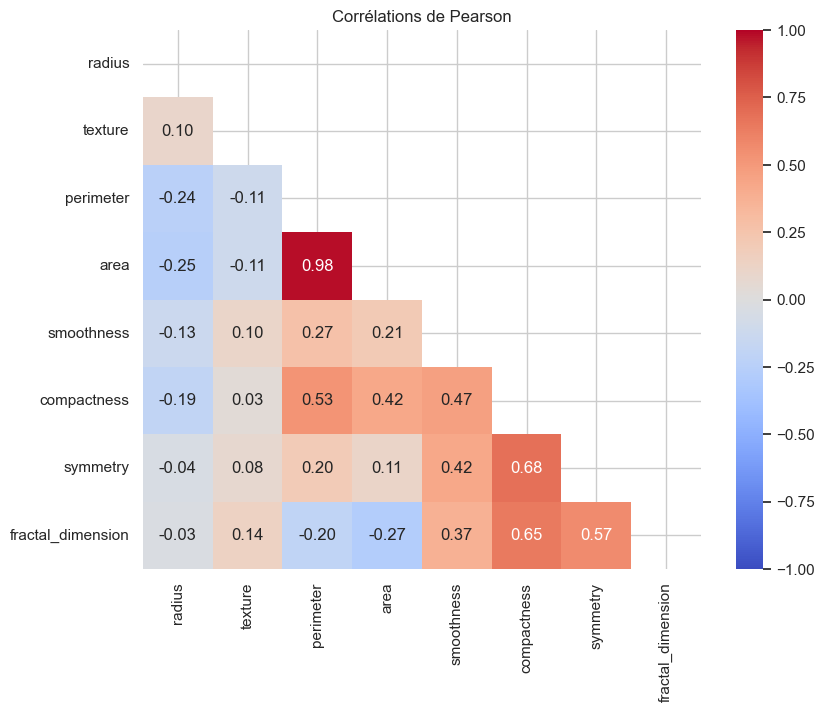

In [10]:
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Corrélations de Pearson")
plt.show()

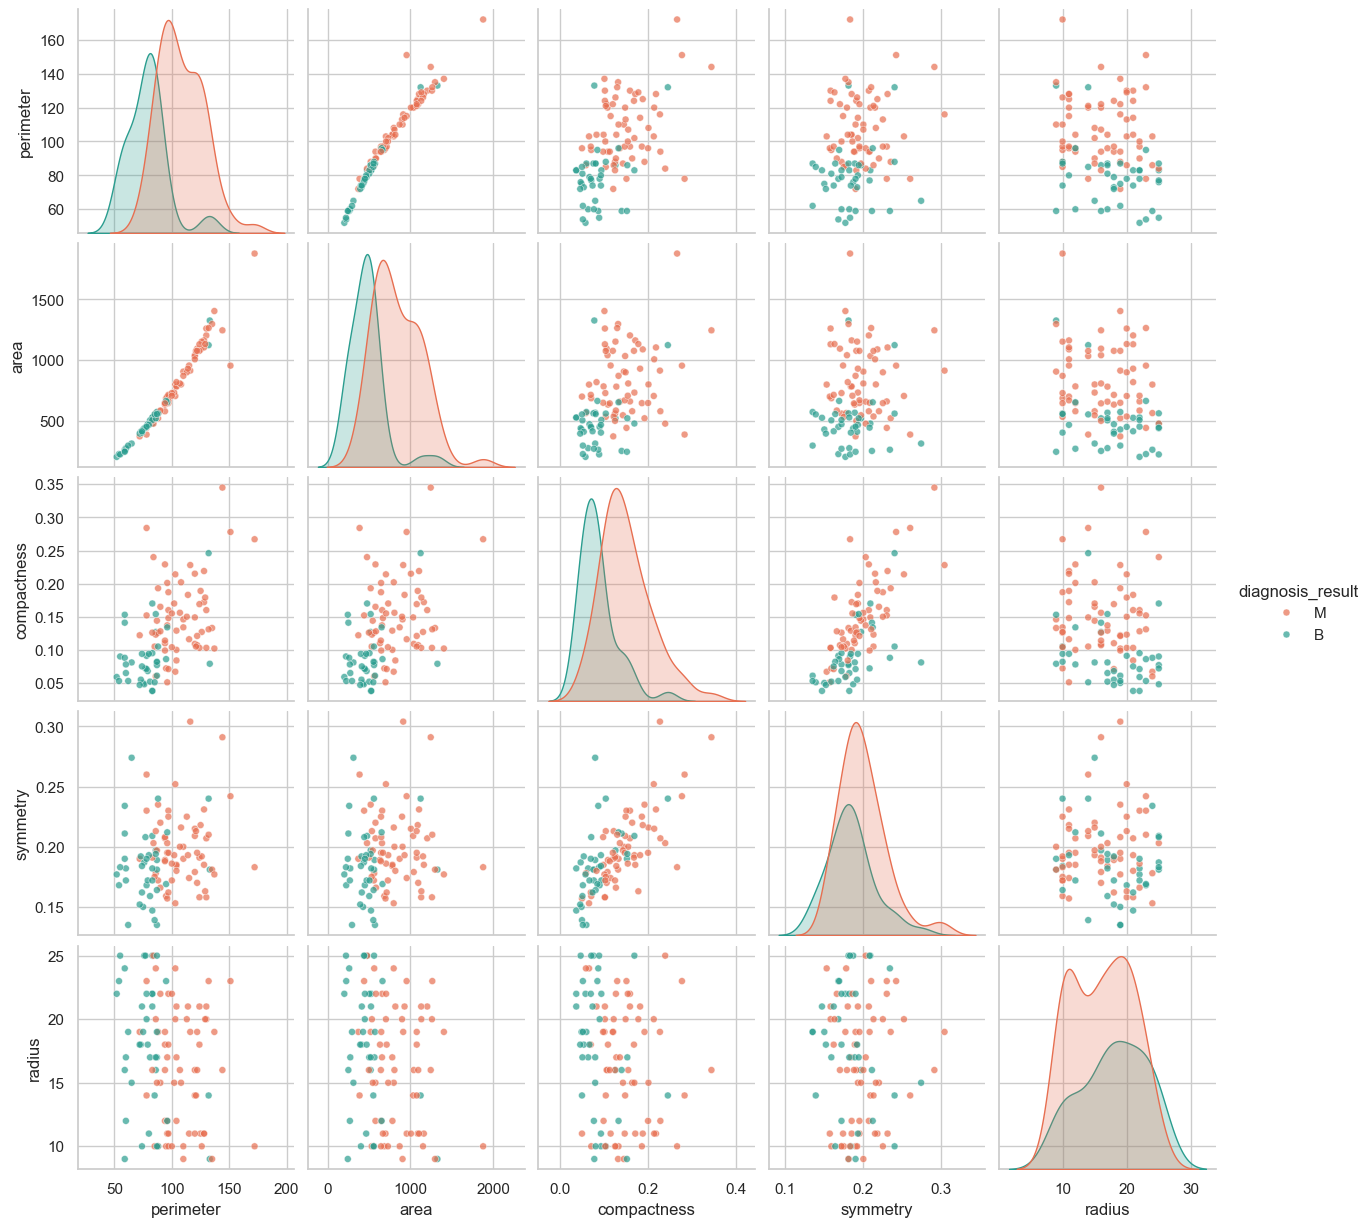

In [11]:
sns.pairplot(df[["perimeter", "area", "compactness", "symmetry", "radius", "diagnosis_result"]],
             hue="diagnosis_result", palette=PAL, diag_kind="kde", plot_kws={"alpha": .7, "s": 25})
plt.show()

- `perimeter` et `area` sont **quasi identiques** (r ≈ 0,98) : redondance, on en garde une seule ou on régularise.
- Les variables de **forme** (`compactness`, `symmetry`, `fractal_dimension`, `smoothness`) forment un second bloc corrélé entre elles (r ≈ 0,4–0,7).
- Les variables de **taille** et de **forme** ne sont que moyennement corrélées (ex. `perimeter`–`compactness` r ≈ 0,53, `area`–`symmetry` r ≈ 0,11) : elles apportent une information en partie complémentaire.
- `radius` et `texture` ne sont corrélées à **aucune** autre variable (|r| < 0,25).

## 7. 🚩 Anomalie : `radius` et `texture` incohérents

Par géométrie, le rayon d'un noyau est lié à son périmètre (P ≈ 2πr) et à son aire (A ≈ πr²). On s'attend donc à une corrélation proche de **+1** entre `radius` et `perimeter`.

corr(radius, perimeter/2π)  = -0.24
corr(radius, √(area/π))     = -0.25
corr(perimeter, √area)      = +0.98  ← cohérent


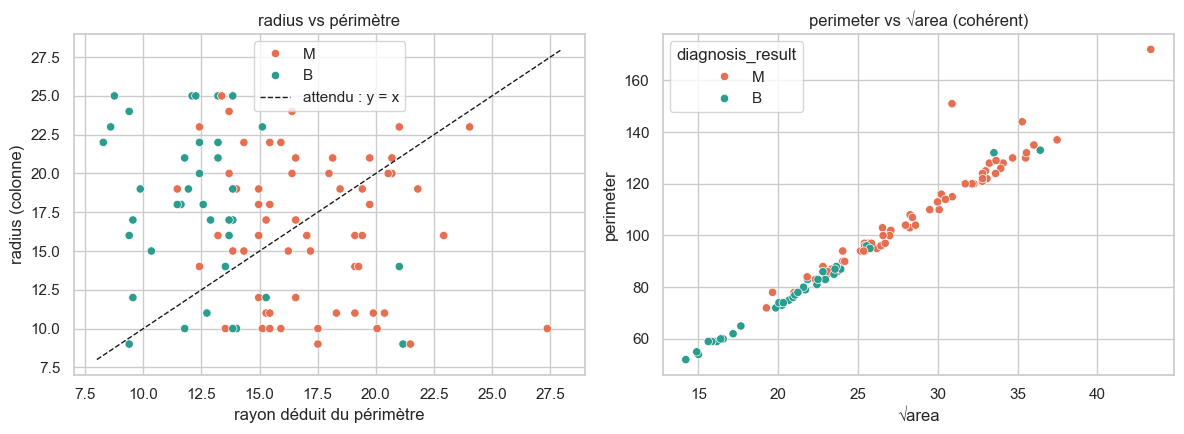

In [12]:
r_perim = df["perimeter"] / (2 * np.pi)
r_area = np.sqrt(df["area"] / np.pi)
print(f"corr(radius, perimeter/2π)  = {np.corrcoef(df.radius, r_perim)[0,1]:+.2f}")
print(f"corr(radius, √(area/π))     = {np.corrcoef(df.radius, r_area)[0,1]:+.2f}")
print(f"corr(perimeter, √area)      = {np.corrcoef(df.perimeter, np.sqrt(df.area))[0,1]:+.2f}  ← cohérent")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=r_perim, y=df.radius, hue=df.diagnosis_result, palette=PAL, ax=axes[0])
axes[0].plot([8, 28], [8, 28], "k--", lw=1, label="attendu : y = x")
axes[0].set(xlabel="rayon déduit du périmètre", ylabel="radius (colonne)", title="radius vs périmètre")
axes[0].legend()
sns.scatterplot(x=np.sqrt(df.area), y=df.perimeter, hue=df.diagnosis_result, palette=PAL, ax=axes[1])
axes[1].set(xlabel="√area", title="perimeter vs √area (cohérent)")
plt.tight_layout(); plt.show()

In [13]:
# Test d'uniformité (Kolmogorov-Smirnov vs loi uniforme sur [min, max])
for col in ["radius", "texture"]:
    lo, hi = df[col].min(), df[col].max()
    p = stats.kstest(df[col], stats.uniform(loc=lo - 0.5, scale=hi - lo + 1).cdf).pvalue
    print(f"{col:8s} : entiers de {lo} à {hi}, {df[col].nunique()} valeurs distinctes, p(uniforme) = {p:.2f}")

radius   : entiers de 9 à 25, 16 valeurs distinctes, p(uniforme) = 0.47
texture  : entiers de 11 à 27, 17 valeurs distinctes, p(uniforme) = 0.04


**Conclusion :** `perimeter` et `area` sont cohérents entre eux, mais `radius` n'a **aucun lien** avec eux. Il se comporte comme un entier tiré au hasard entre 9 et 25 (on ne rejette pas l'hypothèse d'une loi uniforme, p ≈ 0,47). `texture` est suspecte elle aussi : ce sont des entiers de 11 à 27, sans corrélation avec les autres variables et sans pouvoir discriminant (AUC ≈ 0,54). L'uniformité est rejetée de justesse (p ≈ 0,04), mais sa distribution reste très plate.

➡️ Ces deux colonnes sont probablement **corrompues ou générées aléatoirement** lors de la création de ce dataset Kaggle. **Recommandation : les exclure de la modélisation**, ou au minimum le justifier dans le rapport. On peut au besoin recalculer un rayon fiable avec `perimeter / 2π`.

## 8. 🚩 Anomalie : fichier trié selon la cible

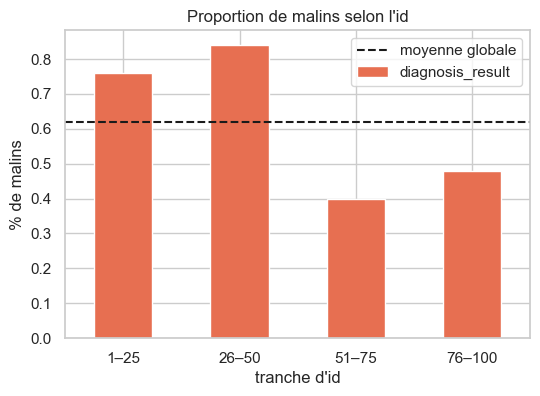

bloc
1–25      0.76
26–50     0.84
51–75     0.40
76–100    0.48
Name: diagnosis_result, dtype: float64


In [14]:
part = (df.assign(bloc=pd.cut(df["id"], bins=[0, 25, 50, 75, 100],
                               labels=["1–25", "26–50", "51–75", "76–100"]))
          .groupby("bloc", observed=True)["diagnosis_result"]
          .apply(lambda s: (s == "M").mean()))
ax = part.plot(kind="bar", color="#e76f51", figsize=(6, 4), rot=0)
ax.axhline((df.diagnosis_result == "M").mean(), ls="--", c="k", label="moyenne globale")
ax.set(ylabel="% de malins", xlabel="tranche d'id", title="Proportion de malins selon l'id")
ax.legend(); plt.show()
print(part.round(2))

➡️ Les malins sont **concentrés en début de fichier**. Si l'on fait un découpage train/test sans mélanger (`shuffle=False`), le train et le test n'auront pas la même proportion de malins. Il faut **mélanger + stratifier** (`train_test_split(..., stratify=y, shuffle=True)`) et **ne pas utiliser `id` comme variable**.

## 9. Valeurs aberrantes

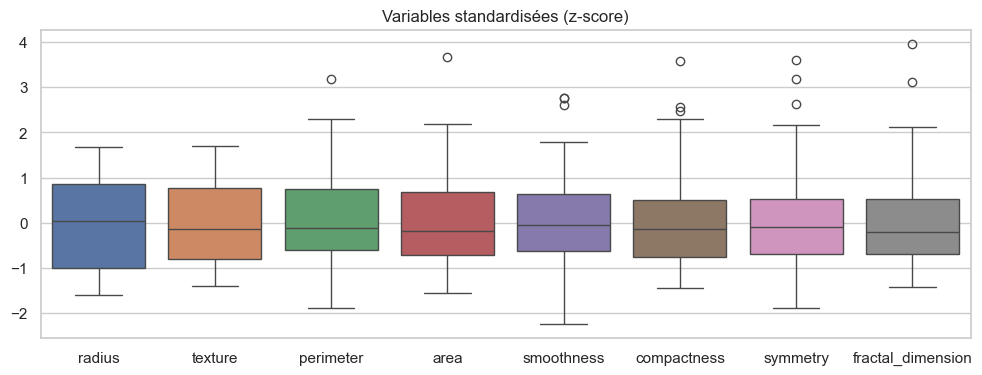

5 patients avec au moins une valeur |z| > 3 :


,id,diagnosis_result,radius,texture,perimeter,area,smoothness,compactness,symmetry,fractal_dimension
3,4,M,14,16,78,386,0.070,0.284,0.260,0.097
25,26,M,19,27,116,913,0.119,0.228,0.304,0.074
71,72,B,9,26,59,244,0.098,0.153,0.190,0.090
78,79,M,16,18,144,1245,0.129,0.345,0.291,0.081
82,83,M,10,15,172,1878,0.106,0.267,0.183,0.068


In [15]:
z = (df[features] - df[features].mean()) / df[features].std()
plt.figure(figsize=(12, 4))
sns.boxplot(data=z); plt.title("Variables standardisées (z-score)"); plt.show()

out = df[(z.abs() > 3).any(axis=1)]
print(f"{len(out)} patients avec au moins une valeur |z| > 3 :")
out[["id", "diagnosis_result"] + features]

Les quelques valeurs extrêmes (grande `area`, forte `compactness`, `fractal_dimension` élevée) correspondent surtout à des **tumeurs malignes** : ce sont des cas réels, pas des erreurs de saisie. On les **conserve**. Si besoin, une transformation log réduira leur influence.

## 10. Vue multivariée (ACP) et modèle de référence

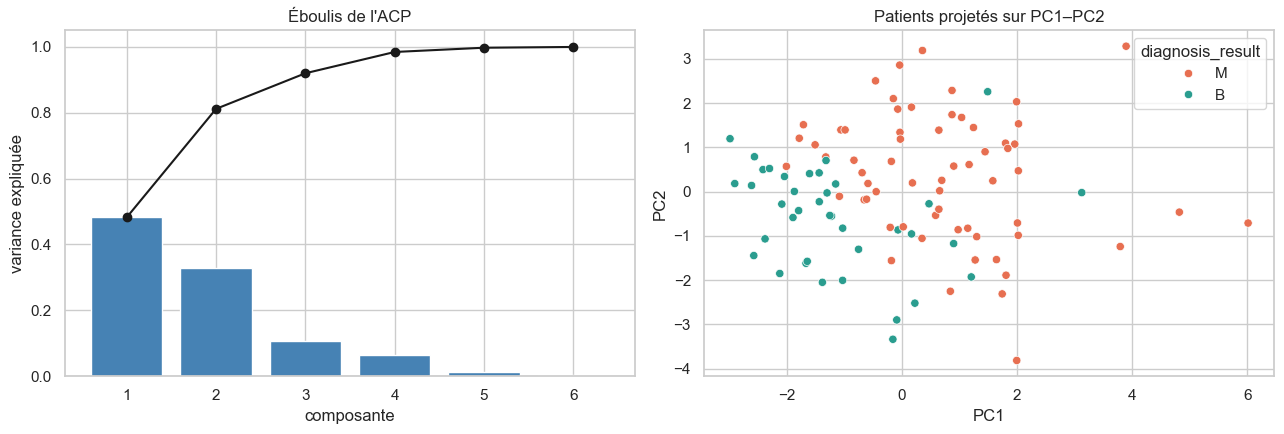

,PC1,PC2
perimeter,0.401,0.514
area,0.352,0.559
smoothness,0.383,-0.130
compactness,0.542,-0.114
symmetry,0.432,-0.293
fractal_dimension,0.297,-0.555


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

fiables = ["perimeter", "area", "smoothness", "compactness", "symmetry", "fractal_dimension"]
Xs = StandardScaler().fit_transform(df[fiables])
pca = PCA().fit(Xs)
pcs = pca.transform(Xs)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, len(fiables) + 1), pca.explained_variance_ratio_, color="steelblue")
axes[0].plot(range(1, len(fiables) + 1), np.cumsum(pca.explained_variance_ratio_), "o-k")
axes[0].set(xlabel="composante", ylabel="variance expliquée", title="Éboulis de l'ACP")
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df.diagnosis_result, palette=PAL, ax=axes[1])
axes[1].set(xlabel="PC1", ylabel="PC2", title="Patients projetés sur PC1–PC2")
plt.tight_layout(); plt.show()

pd.DataFrame(pca.components_[:2].T, index=fiables, columns=["PC1", "PC2"])

Les deux premières composantes résument les deux familles de variables, **taille** et **forme**. Les patients B et M se séparent assez bien dans ce plan, avec une zone de chevauchement.

In [17]:
# Modèle de référence (simple régression logistique, validation croisée stratifiée)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
jeux = {
    "toutes les variables": features,
    "sans radius/texture": fiables,
    "perimeter seul": ["perimeter"],
    "radius + texture seuls": ["radius", "texture"],
}
res = {}
for nom, cols in jeux.items():
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(model, df[cols], y, cv=cv, scoring="roc_auc")
    res[nom] = {"AUC moyenne": s.mean(), "écart-type": s.std()}
pd.DataFrame(res).T

,AUC moyenne,écart-type
toutes les variables,0.910,0.065
sans radius/texture,0.908,0.059
perimeter seul,0.882,0.111
radius + texture seuls,0.592,0.070


➡️ Retirer `radius` et `texture` **ne dégrade pas** la performance. Seules, ces deux variables ne prédisent quasiment rien. Cela confirme qu'elles ne portent pas d'information utile.

## 11. Synthèse des tendances

**Qualité**
1. 100 patients, 8 variables, aucune valeur manquante ni doublon.
2. Cible déséquilibrée : 62 % M / 38 % B → validation croisée stratifiée, AUC et rappel comme métriques.
3. Le fichier est **trié** (80 % de malins dans les 50 premiers id, 44 % dans les 50 derniers) → toujours mélanger, ne pas utiliser `id`.

**Tendances cliniques**

4. **La taille du noyau est le signal principal** : les tumeurs malignes ont un périmètre ~37 % plus grand et une aire ~78 % plus grande (AUC ≈ 0,88).
5. **La forme compte aussi** : les noyaux malins sont plus compacts / irréguliers (`compactness` +74 %, AUC ≈ 0,84), un peu plus asymétriques et moins lisses.
6. `texture` et `fractal_dimension` n'apportent rien seules.

**Points d'attention**

7. 🚩 **`radius` et `texture` semblent aléatoires** : `radius` n'est pas corrélé au périmètre (r ≈ −0,24 au lieu de ≈ +1) et sa distribution est uniforme → à exclure.
8. **Redondance** `perimeter` / `area` (r ≈ 0,98) et bloc corrélé des variables de forme → régularisation ou sélection de variables.
9. Variables asymétriques (`area`, `compactness`, `fractal_dimension`) → transformation log possible.
10. Les variables sont celles du dataset *Breast Cancer Wisconsin* : la provenance « prostate » est à discuter dans le rapport.
11. Échantillon petit (n = 100) → modèles simples, validation croisée, intervalles de confiance sur les métriques.